# Assignment 7 — Random Forest Feature Selection

**Dataset:** [Wine](https://archive.ics.uci.edu/dataset/109/wine), UCI Machine Learning Repository. 178 wines from three different cultivars (grape varieties) grown in the same region of Italy, each described by 13 chemical measurements.
**Task:** multi-class classification (cultivar 0 / 1 / 2). I use a **Random Forest** to rank the features by importance, then measure what happens when the model is retrained on **only the five most important features**.

*Choice of dataset:* the assignment allows the Wine dataset or IBM HR Attrition. I chose Wine because its 13 features are all continuous chemical measurements with clear physical meaning, so the importance ranking can be interpreted and checked against domain knowledge. It is also clean and balanced enough that differences between the two models reflect feature selection and not class imbalance.

| Requirement | Section |
|---|---|
| Use the Wine (or IBM HR) dataset | 1 |
| Train a baseline Random Forest using all features | 2 |
| Identify and visualise feature importance | 3 |
| Retrain the model using the top five features | 4 |
| Compare both models: accuracy, simplicity and interpretability | 5–7 |

## 0. Setup

In [1]:
import pickle
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import spearmanr
from sklearn.datasets import load_wine
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, log_loss
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, export_text

SEED = 42
FIG_DIR, RES_DIR = Path("figures"), Path("results")
for d in (FIG_DIR, RES_DIR):
    d.mkdir(exist_ok=True)

In [2]:
# Plot style: one consistent, colour-blind-checked palette for every figure
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.labelsize": 10, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.prop_cycle": cycler(color=PALETTE), "lines.linewidth": 2, "lines.markersize": 6,
    "legend.frameon": False, "text.color": INK, "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight", "font.size": 10,
})
CLASS_COLORS = [PALETTE[0], PALETTE[1], PALETTE[2]]
MODEL_COLORS = {"All 13 features": PALETTE[0], "Top 5 features": PALETTE[1]}

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 1. Load and inspect the data

scikit-learn includes an exact copy of the UCI Wine dataset, so no download is needed.

In [3]:
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
X.columns = [c.replace("od280/od315_of_diluted_wines", "od280/od315") for c in X.columns]
FEATURES = list(X.columns)
print(f"samples: {X.shape[0]}, features: {X.shape[1]}, classes: {wine.target_names.tolist()}")
print("class sizes:", y.value_counts().sort_index().to_dict())
print("missing values:", int(X.isna().sum().sum()), "| duplicate rows:", int(X.duplicated().sum()))
X.describe().T[["mean", "std", "min", "max"]].round(2)

samples: 178, features: 13, classes: ['class_0', 'class_1', 'class_2']
class sizes: {0: 59, 1: 71, 2: 48}
missing values: 0 | duplicate rows: 0


,mean,std,min,max
alcohol,13.00,0.81,11.03,14.83
malic_acid,2.34,1.12,0.74,5.80
ash,2.37,0.27,1.36,3.23
alcalinity_of_ash,19.49,3.34,10.60,30.00
magnesium,99.74,14.28,70.00,162.00
total_phenols,2.30,0.63,0.98,3.88
flavanoids,2.03,1.00,0.34,5.08
nonflavanoid_phenols,0.36,0.12,0.13,0.66
proanthocyanins,1.59,0.57,0.41,3.58
color_intensity,5.06,2.32,1.28,13.00


The data is clean, with no missing values and no duplicates, and the three classes are reasonably balanced (59 / 71 / 48). The features have very different scales (proline is in the hundreds, hue is around 1). Random Forests split on thresholds, so they are **insensitive to feature scale** and no scaling is needed.

**Split:** a stratified 70/30 train/test split (124 / 54 wines). Feature importances are computed **on the training set only**. If the test set were used to choose the "top 5", the selection would leak test information and the reduced model's test score would be optimistically biased.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print(f"train: {X_train.shape}, test: {X_test.shape}")

train: (124, 13), test: (54, 13)


## 2. Baseline Random Forest: all 13 features

A Random Forest trains many decision trees, each on a **bootstrap sample** of the training rows and considering a **random subset of features** at each split, and averages their votes. Averaging many decorrelated trees greatly reduces variance compared with a single tree.

Settings: 500 trees (enough for stable importances), default `max_features="sqrt"` (about 3–4 candidate features per split), fully grown trees. With `oob_score=True` each tree is also scored on the ~37% of rows it did *not* see in its bootstrap sample. This **out-of-bag (OOB)** accuracy is a free, built-in validation estimate.

In [5]:
def make_rf(seed=SEED):
    return RandomForestClassifier(n_estimators=500, oob_score=True, n_jobs=-1, random_state=seed)

def fit_and_score(feats, label):
    rf = make_rf()
    t0 = time.perf_counter(); rf.fit(X_train[feats], y_train); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    for _ in range(20):
        proba = rf.predict_proba(X_test[feats])
    pred_ms = (time.perf_counter() - t0) / 20 * 1000
    pred = proba.argmax(axis=1)
    info = {"model": label, "n_features": len(feats), "test accuracy": accuracy_score(y_test, pred),
            "test macro-F1": f1_score(y_test, pred, average="macro"), "test log-loss": log_loss(y_test, proba),
            "OOB accuracy": rf.oob_score_, "fit time (s)": fit_s, "predict time (ms)": pred_ms,
            "total tree nodes": int(sum(e.tree_.node_count for e in rf.estimators_)),
            "mean tree depth": float(np.mean([e.get_depth() for e in rf.estimators_])),
            "model size (KB)": len(pickle.dumps(rf)) / 1024}
    return rf, pred, info

rf_all, pred_all, info_all = fit_and_score(FEATURES, "All 13 features")
print(f"Baseline: test accuracy {info_all['test accuracy']:.3f} | macro-F1 {info_all['test macro-F1']:.3f} | "
      f"OOB accuracy {info_all['OOB accuracy']:.3f}")
print(classification_report(y_test, pred_all, target_names=wine.target_names, digits=3))

Baseline: test accuracy 1.000 | macro-F1 1.000 | OOB accuracy 0.976
              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        18
     class_1      1.000     1.000     1.000        21
     class_2      1.000     1.000     1.000        15

    accuracy                          1.000        54
   macro avg      1.000     1.000     1.000        54
weighted avg      1.000     1.000     1.000        54



The baseline classifies **every test wine correctly**. Its OOB accuracy, an estimate from all 124 training wines, is slightly lower, which is a reminder that a 54-sample test set gives a coarse estimate: one error would move accuracy by 1.9 points. I return to this in Section 5 with repeated cross-validation.

## 3. Feature importance

I use two complementary measures:
* **Mean Decrease in Impurity (MDI)**, the built-in `feature_importances_`. It is the total reduction in Gini impurity contributed by splits on each feature, averaged over all 500 trees. It is fast and computed on the training data. (Individual trees disagree a lot, because each one only sees random feature subsets, but the average over 500 trees is stable.)
* **Permutation importance**: shuffle one feature in the *test* set and measure how much accuracy drops. Breaking the link between a feature and the target shows how much the model really relies on it for unseen data. It works as a cross-check, because MDI can be biased toward high-cardinality continuous features.

In [6]:
mdi = pd.DataFrame({"importance": rf_all.feature_importances_,
                    "std": np.std([t.feature_importances_ for t in rf_all.estimators_], axis=0)},
                   index=FEATURES).sort_values("importance", ascending=False)
perm = permutation_importance(rf_all, X_test, y_test, n_repeats=50, random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({"importance": perm.importances_mean, "std": perm.importances_std},
                       index=FEATURES).sort_values("importance", ascending=False)
TOP5 = list(mdi.index[:5])
print("Top 5 features by MDI (training set):", TOP5)
print("Top 5 by permutation (test set):      ", list(perm_df.index[:5]))
rho = spearmanr(mdi["importance"], perm_df.loc[mdi.index, "importance"]).statistic
print(f"Spearman rank correlation between the two rankings: {rho:.2f}")
print("correlation flavanoids–od280/od315:", round(X["flavanoids"].corr(X["od280/od315"]), 2),
      "| flavanoids–total_phenols:", round(X["flavanoids"].corr(X["total_phenols"]), 2))
mdi.assign(rank=range(1, 14), cumulative=mdi["importance"].cumsum()).round(3)

Top 5 features by MDI (training set): ['color_intensity', 'alcohol', 'flavanoids', 'proline', 'hue']
Top 5 by permutation (test set):       ['proline', 'alcohol', 'color_intensity', 'flavanoids', 'magnesium']
Spearman rank correlation between the two rankings: 0.84
correlation flavanoids–od280/od315: 0.79 | flavanoids–total_phenols: 0.86


,importance,std,rank,cumulative
color_intensity,0.162,0.175,1,0.162
alcohol,0.151,0.176,2,0.314
flavanoids,0.148,0.173,3,0.461
proline,0.144,0.173,4,0.605
hue,0.097,0.133,5,0.703
od280/od315,0.094,0.136,6,0.797
total_phenols,0.057,0.103,7,0.854
magnesium,0.033,0.066,8,0.887
malic_acid,0.032,0.063,9,0.920
alcalinity_of_ash,0.028,0.060,10,0.947


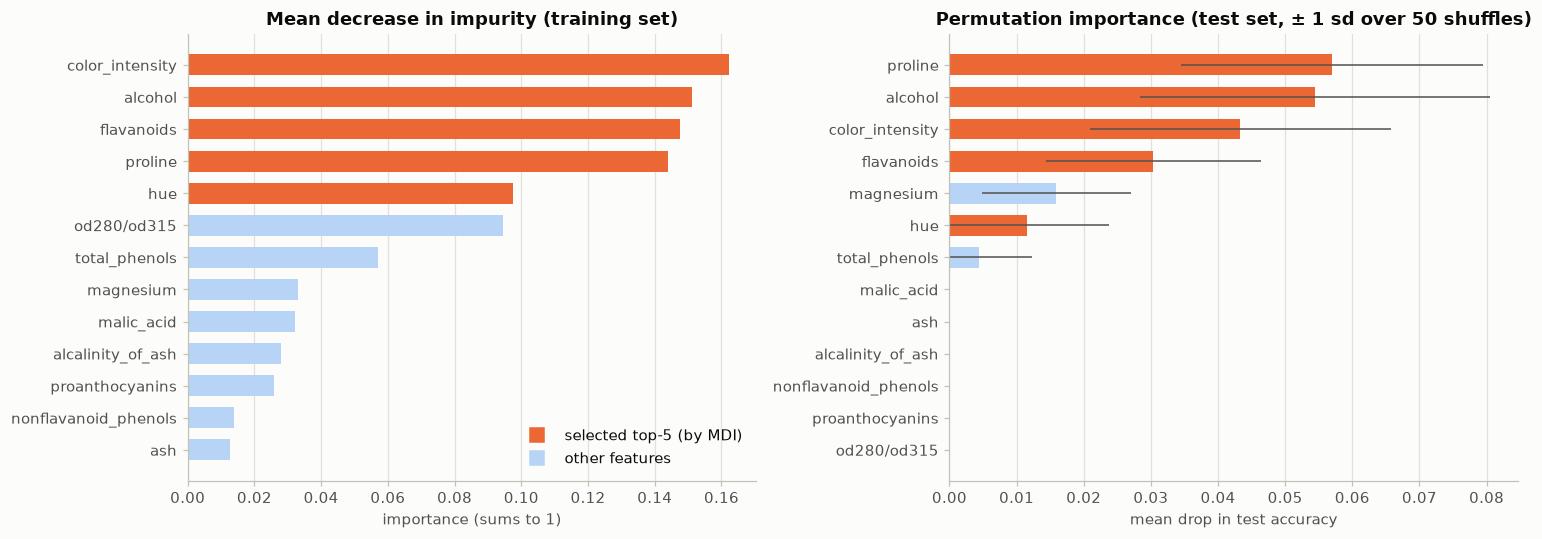

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, df_, title, xl, err in [(axes[0], mdi, "Mean decrease in impurity (training set)", "importance (sums to 1)", False),
                                (axes[1], perm_df, "Permutation importance (test set, ± 1 sd over 50 shuffles)",
                                 "mean drop in test accuracy", True)]:
    d = df_.iloc[::-1]
    colors = [PALETTE[1] if f in TOP5 else "#b7d3f6" for f in d.index]
    ax.barh(d.index, d["importance"], xerr=d["std"] if err else None, color=colors, height=0.65,
            error_kw=dict(ecolor=INK2, lw=1))
    ax.set_xlabel(xl); ax.set_title(title); ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
axes[0].plot([], [], "s", color=PALETTE[1], markersize=9, label="selected top-5 (by MDI)")
axes[0].plot([], [], "s", color="#b7d3f6", markersize=9, label="other features")
axes[0].legend(loc="lower right")
fig.tight_layout(); save(fig, "01_feature_importance")

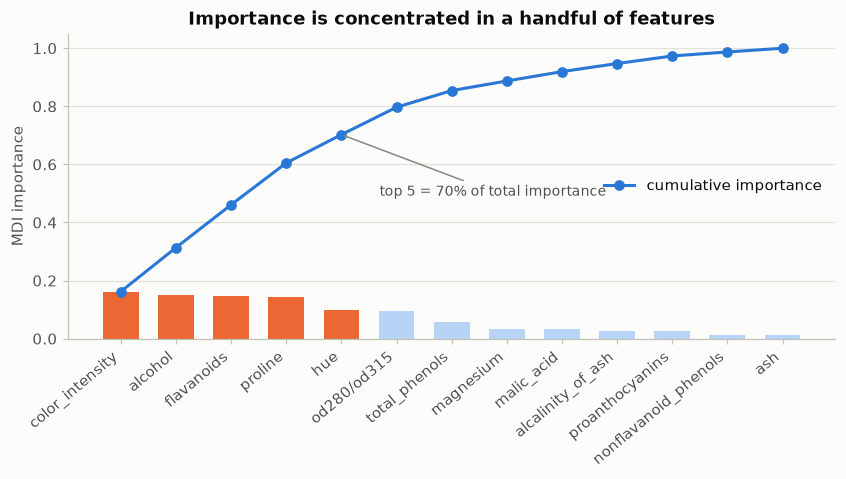

In [8]:
cum = mdi["importance"].cumsum()
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(range(1, 14), mdi["importance"], color=[PALETTE[1]] * 5 + ["#b7d3f6"] * 8, width=0.65)
ax.plot(range(1, 14), cum, color=PALETTE[0], marker="o", label="cumulative importance")
ax.annotate(f"top 5 = {cum.iloc[4]:.0%} of total importance", (5, cum.iloc[4]), xytext=(25, -40),
            textcoords="offset points", color=INK2, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_xticks(range(1, 14), mdi.index, rotation=40, ha="right"); ax.set_ylabel("MDI importance")
ax.set_ylim(0, 1.05); ax.legend(loc="center right"); ax.grid(axis="x", visible=False)
ax.set_title("Importance is concentrated in a handful of features")
save(fig, "02_cumulative_importance")

**What the importances show**
* MDI ranks **colour intensity, alcohol, flavanoids, proline and hue** as the top five. Together they account for **70% of the total importance**, while the five least useful features (malic acid, alcalinity of ash, proanthocyanins, non-flavanoid phenols, ash) share only about 11%.
* Permutation importance **agrees on four of the five** (proline, alcohol, colour intensity, flavanoids), and the two full rankings are strongly correlated (Spearman ρ = 0.84). It places magnesium marginally above hue, and gives `od280/od315` and `total_phenols` almost no importance.
* That difference is expected. `od280/od315` and `total_phenols` are strongly **correlated with flavanoids** (printed above). When one of them is shuffled, the forest falls back on its correlated partner and accuracy barely drops, so permutation importance *under-rates* redundant features. MDI instead *shares* credit among correlated features. Both views agree that a small set of chemical properties carries most of the information.
* The chemistry is plausible: colour intensity and hue reflect pigments, flavanoids are the main phenolic compounds, and proline (an amino acid) and alcohol content differ between grape varieties.

## 4. Retrain the Random Forest on the top five features

In [9]:
rf_top5, pred_top5, info_top5 = fit_and_score(TOP5, "Top 5 features")
print("features used:", TOP5)
print(f"Top-5 model: test accuracy {info_top5['test accuracy']:.3f} | macro-F1 {info_top5['test macro-F1']:.3f} | "
      f"OOB accuracy {info_top5['OOB accuracy']:.3f}")
print(classification_report(y_test, pred_top5, target_names=wine.target_names, digits=3))

features used: ['color_intensity', 'alcohol', 'flavanoids', 'proline', 'hue']
Top-5 model: test accuracy 1.000 | macro-F1 1.000 | OOB accuracy 0.952
              precision    recall  f1-score   support

     class_0      1.000     1.000     1.000        18
     class_1      1.000     1.000     1.000        21
     class_2      1.000     1.000     1.000        15

    accuracy                          1.000        54
   macro avg      1.000     1.000     1.000        54
weighted avg      1.000     1.000     1.000        54



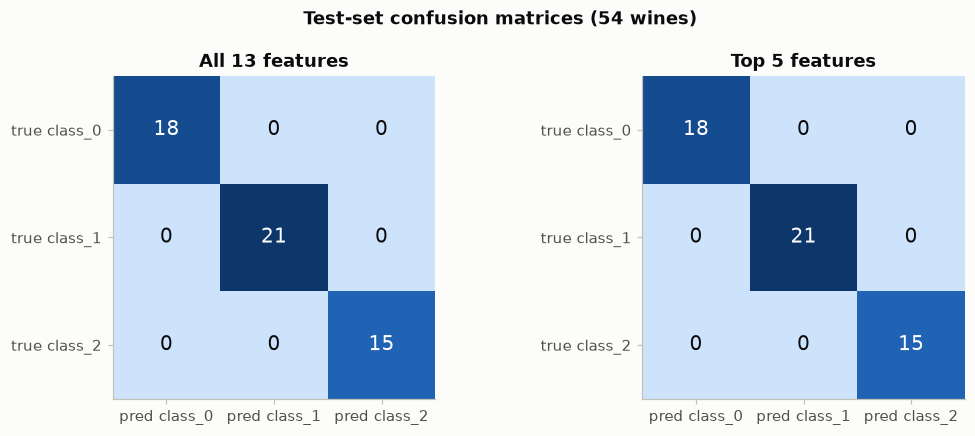

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, pred, title in [(axes[0], pred_all, "All 13 features"), (axes[1], pred_top5, "Top 5 features")]:
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap=BLUES)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, str(v), ha="center", va="center", fontsize=13, color="white" if v > cm.max() * 0.5 else INK)
    ax.set_xticks(range(3), [f"pred {c}" for c in wine.target_names])
    ax.set_yticks(range(3), [f"true {c}" for c in wine.target_names]); ax.grid(False); ax.set_title(title)
fig.suptitle("Test-set confusion matrices (54 wines)", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "03_confusion_matrices")

## 5. Comparing accuracy robustly

Both models are close to perfect on the small test set, so it cannot tell them apart. To measure the real accuracy cost of dropping 8 features I use **repeated stratified 5-fold cross-validation (10 repeats = 50 folds)** on all 178 wines.

This must be done carefully. The top-5 selection has to happen **inside each training fold**: a fresh Random Forest ranks the features on that fold's training data, keeps the five best, and the final forest is trained on those. If I reused `TOP5` (chosen once on the training set) the estimate would be biased upward. The pipeline `SelectFromModel(RF, max_features=k) → RF` handles this.

In [11]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)

def selection_pipeline(k):
    if k == len(FEATURES):
        return Pipeline([("rf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED))])
    return Pipeline([
        ("select", SelectFromModel(RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
                                   max_features=k, threshold=-np.inf)),
        ("rf", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)),
    ])

curve = []
t0 = time.perf_counter()
for k in range(1, len(FEATURES) + 1):
    s = cross_validate(selection_pipeline(k), X, y, cv=rcv, scoring=["accuracy", "f1_macro", "neg_log_loss"], n_jobs=-1)
    curve.append({"k": k, "accuracy": s["test_accuracy"].mean(), "accuracy sd": s["test_accuracy"].std(),
                  "macro-F1": s["test_f1_macro"].mean(), "log-loss": -s["test_neg_log_loss"].mean(),
                  "fold_acc": s["test_accuracy"]})
curve = pd.DataFrame(curve).set_index("k")
print(f"cross-validation done in {time.perf_counter() - t0:.0f}s")
curve.drop(columns="fold_acc").round(4).to_csv(RES_DIR / "accuracy_vs_n_features.csv")
curve.drop(columns="fold_acc").round(4).T

cross-validation done in 102s


k,1,2,3,4,5,6,7,8,9,10,11,12,13
accuracy,0.6909,0.8758,0.9538,0.9679,0.9702,0.9724,0.9741,0.9752,0.9758,0.9763,0.9758,0.9797,0.9792
accuracy sd,0.0723,0.0510,0.0365,0.0297,0.0295,0.0268,0.0269,0.0251,0.0253,0.0221,0.0252,0.0218,0.0250
macro-F1,0.6896,0.8767,0.9554,0.9685,0.9708,0.9733,0.9750,0.9758,0.9764,0.9770,0.9764,0.9802,0.9797
log-loss,2.3128,0.5308,0.1470,0.1183,0.1255,0.1201,0.1265,0.1315,0.1263,0.1286,0.1319,0.1328,0.1388


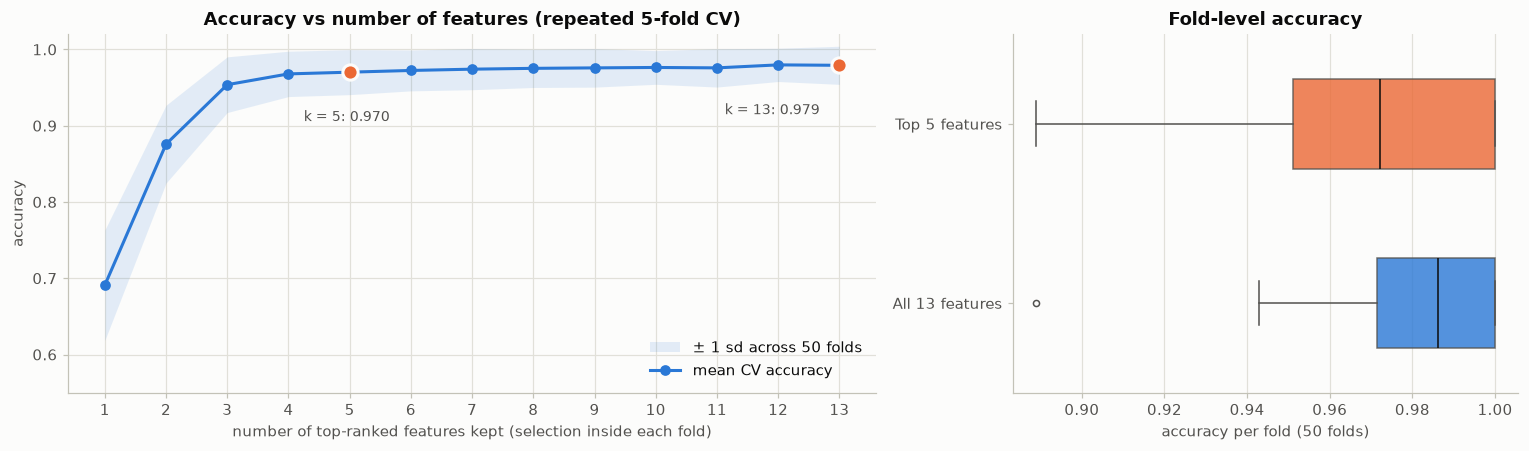

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.fill_between(curve.index, curve["accuracy"] - curve["accuracy sd"], curve["accuracy"] + curve["accuracy sd"],
                color=PALETTE[0], alpha=0.12, linewidth=0, label="± 1 sd across 50 folds")
ax.plot(curve.index, curve["accuracy"], color=PALETTE[0], marker="o", label="mean CV accuracy")
for k, dx in ((5, -30), (13, -75)):
    ax.plot(k, curve.loc[k, "accuracy"], "o", color=PALETTE[1], markersize=10, markeredgecolor=SURFACE, markeredgewidth=2)
    ax.annotate(f"k = {k}: {curve.loc[k, 'accuracy']:.3f}", (k, curve.loc[k, "accuracy"]),
                xytext=(dx, -32), textcoords="offset points", color=INK2, fontsize=9)
ax.set_xticks(range(1, 14)); ax.set_xlabel("number of top-ranked features kept (selection inside each fold)")
ax.set_ylabel("accuracy"); ax.set_ylim(0.55, 1.02); ax.legend(loc="lower right")
ax.set_title("Accuracy vs number of features (repeated 5-fold CV)")

ax = axes[1]
data = [curve.loc[13, "fold_acc"], curve.loc[5, "fold_acc"]]
bp = ax.boxplot(data, orientation="horizontal", tick_labels=["All 13 features", "Top 5 features"], widths=0.5,
                patch_artist=True, medianprops=dict(color=INK), whiskerprops=dict(color=INK2),
                capprops=dict(color=INK2), flierprops=dict(markersize=4, markeredgecolor=INK2))
for patch, c in zip(bp["boxes"], [PALETTE[0], PALETTE[1]]):
    patch.set(facecolor=c, alpha=0.8, edgecolor=INK2)
ax.set_xlabel("accuracy per fold (50 folds)"); ax.grid(axis="y", visible=False)
ax.set_title("Fold-level accuracy")
fig.tight_layout(); save(fig, "04_accuracy_vs_n_features")

## 6. Side-by-side comparison

In [13]:
comparison = pd.DataFrame([info_all, info_top5]).set_index("model")
comparison["CV accuracy (50 folds)"] = [curve.loc[13, "accuracy"], curve.loc[5, "accuracy"]]
comparison["CV accuracy sd"] = [curve.loc[13, "accuracy sd"], curve.loc[5, "accuracy sd"]]
comparison["CV macro-F1"] = [curve.loc[13, "macro-F1"], curve.loc[5, "macro-F1"]]
comparison["CV log-loss"] = [curve.loc[13, "log-loss"], curve.loc[5, "log-loss"]]
comparison = comparison[["n_features", "test accuracy", "test macro-F1", "OOB accuracy", "CV accuracy (50 folds)",
                         "CV accuracy sd", "CV macro-F1", "CV log-loss", "test log-loss", "total tree nodes",
                         "mean tree depth", "model size (KB)", "fit time (s)", "predict time (ms)"]]
comparison.to_csv(RES_DIR / "model_comparison.csv")
comparison.round(4).astype({"n_features": int, "total tree nodes": int}).astype(object).T

model,All 13 features,Top 5 features
n_features,13,5
test accuracy,1.0,1.0
test macro-F1,1.0,1.0
OOB accuracy,0.9758,0.9516
CV accuracy (50 folds),0.9792,0.9702
CV accuracy sd,0.025,0.0295
CV macro-F1,0.9797,0.9708
CV log-loss,0.1388,0.1255
test log-loss,0.1391,0.1047
total tree nodes,8976,8244


### Interpretability: what can a human see with five features?

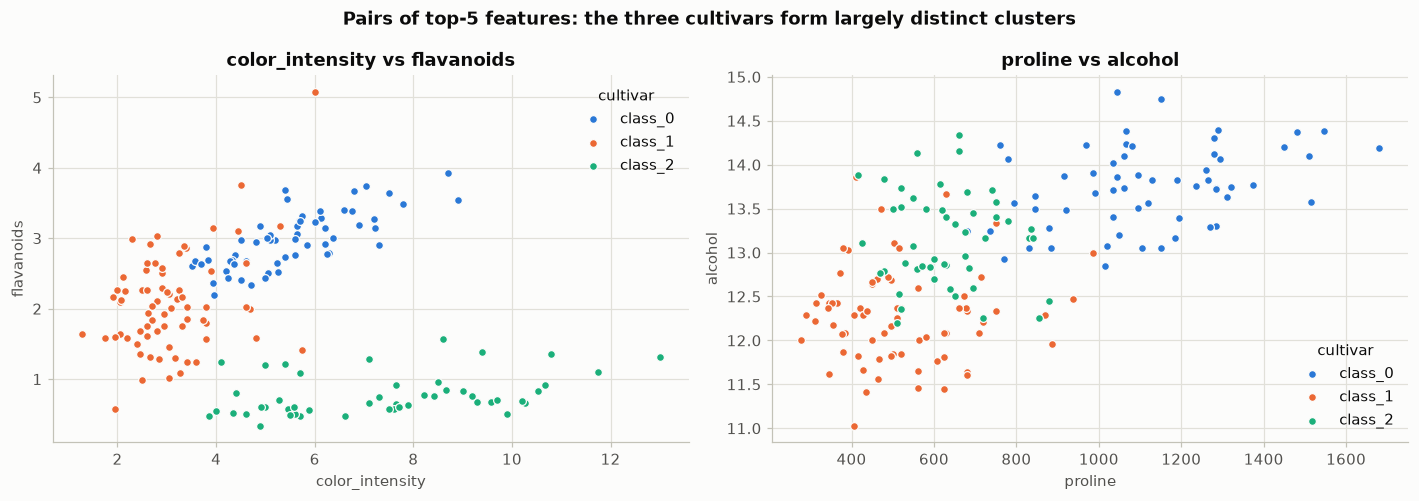

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
pairs = [(TOP5[0], TOP5[2]), (TOP5[3], TOP5[1])]
for ax, (fx, fy) in zip(axes, pairs):
    for c in range(3):
        mk = y == c
        ax.scatter(X.loc[mk, fx], X.loc[mk, fy], s=26, color=CLASS_COLORS[c], edgecolor=SURFACE, linewidth=0.8,
                   label=wine.target_names[c])
    ax.set_xlabel(fx); ax.set_ylabel(fy); ax.legend(loc="best", title="cultivar")
    ax.set_title(f"{fx} vs {fy}")
fig.suptitle("Pairs of top-5 features: the three cultivars form largely distinct clusters", fontweight="bold", color=INK)
fig.tight_layout(); save(fig, "05_top_feature_scatter")

A forest of 500 trees is never fully transparent. But with only five well-understood chemical measurements, the reduced model can be summarised by a **single shallow decision tree** that a person can read. Its accuracy shows how much of the forest's behaviour simple rules can capture:

In [15]:
tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X_train[TOP5], y_train)
tree_cv = cross_validate(DecisionTreeClassifier(max_depth=3, random_state=SEED), X[TOP5], y, cv=rcv)["test_score"]
print(f"Depth-3 decision tree on the top-5 features: test accuracy {tree.score(X_test[TOP5], y_test):.3f}, "
      f"CV accuracy {tree_cv.mean():.3f} ± {tree_cv.std():.3f}\n")
print(export_text(tree, feature_names=TOP5, class_names=list(wine.target_names), decimals=2))

Depth-3 decision tree on the top-5 features: test accuracy 0.981, CV accuracy 0.926 ± 0.050

|--- color_intensity <= 3.82
|   |--- alcohol <= 13.02
|   |   |--- class: class_1
|   |--- alcohol >  13.02
|   |   |--- proline <= 651.00
|   |   |   |--- class: class_1
|   |   |--- proline >  651.00
|   |   |   |--- class: class_0
|--- color_intensity >  3.82
|   |--- flavanoids <= 1.58
|   |   |--- hue <= 0.97
|   |   |   |--- class: class_2
|   |   |--- hue >  0.97
|   |   |   |--- class: class_1
|   |--- flavanoids >  1.58
|   |   |--- proline <= 724.50
|   |   |   |--- class: class_1
|   |   |--- proline >  724.50
|   |   |   |--- class: class_0



## 7. Impact on accuracy, simplicity and interpretability

**Accuracy**
* On the 54-wine test set **both models are 100% correct**, so the test set alone cannot separate them.
* Repeated cross-validation (50 folds, with selection redone inside every fold) measures the real cost. Accuracy goes from **97.9% ± 2.5 with all 13 features to 97.0% ± 3.0 with the top 5**, a drop of under one percentage point. The OOB estimate tells the same story (97.6% → 95.2%).
* The accuracy-vs-k curve shows **diminishing returns**. Accuracy climbs steeply up to 3–4 features (96.8% with 4) and then plateaus. The last 8 features add less than one point between them.
* The top-5 model's **probabilities are actually better**: lower log-loss in CV (0.126 vs 0.139) and on the test set (0.105 vs 0.139). Without the weak features, fewer trees split on noise, so the forest's votes are more confident when it is right.

**Simplicity**
* **Input dimensionality falls by 62% (13 → 5).** In practice only five laboratory measurements per wine are needed instead of thirteen. Data collection is cheaper and faster, there are fewer chances for missing values, and the model is less exposed to irrelevant variation.
* The **forest itself barely shrinks**: total tree nodes fall only 8% (8,976 → 8,244), and model size, training time and prediction time are almost unchanged. Fully grown trees keep splitting until their leaves are pure, so their size depends on the number of training samples, not the number of features. The simplification is in the *inputs*, not in the model internals.

**Interpretability**
* With five meaningful chemical features, the model can be explained **globally**: the scatter plots show that the cultivars form distinct clusters in just two of these dimensions.
* A **single depth-3 decision tree** on the same five features gives a handful of human-readable rules (printed above) that classify **98.1% of the test wines and 92.6% in cross-validation** correctly, so most of the forest's behaviour can be summarised in a few if-then statements.
* A 500-tree forest stays a black box at the level of individual predictions whichever feature set it uses. Feature selection mainly improves **global** interpretability (which variables matter and how), and makes the model easier for domain experts to check.

## 8. Conclusion

* A **baseline Random Forest** on all 13 chemical features classifies the three wine cultivars almost perfectly (100% test accuracy, 97.9% repeated-CV accuracy).
* **Feature importance** (MDI, confirmed by permutation importance) is highly concentrated: **colour intensity, alcohol, flavanoids, proline and hue** carry 70% of the total importance.
* **Retraining on only these five features** costs less than one point of cross-validated accuracy (97.9% → 97.0%), keeps 100% test accuracy, and even improves probability calibration (lower log-loss). Feature selection was done inside every CV fold, so this estimate is not biased by leakage.
* **Trade-off:** the reduced model needs 62% fewer measurements and is much easier to explain (a depth-3 tree on the same features reaches about 93% CV accuracy). The forest itself, however, is only marginally smaller or faster.

**Recommendation:** for this dataset the **top-5 model is the better practical choice**. It gives up less than one point of accuracy in exchange for a much simpler, cheaper and more interpretable model. If every measurement is available anyway and the last fraction of a percent matters, the 13-feature model remains slightly more accurate.